# Example calculation of Radial Distribution Function (RDF)
While many efficient implementations of RDF calculations already exist (LAMMPS, OVITO, MDAnalysis, just to name those I know of), I wanted to calculate them for the center of mass of disulfide bonds, and have a general implementation that worked with the rest of my framework.
That is why I wrote my own implementation, which lets me work directly with xarray.

Fair warning that my own version is a lot slower than those listed above, but it gives the same results as LAMMPS and OVITO.

In [1]:
from vast_pea.lammps_traj import trajectory
from vast_pea.lammps_bonds import bond_dynamics
from vast_pea.computers import compute_rdf

import matplotlib.pyplot as plt

## Read trajectory from saved netCDF file
For more information on generating those saved netCDF files, check `0_preprocess/extract_trajectory.py`

In [2]:
traj = trajectory(path="../../data/BER/save/",
                  pattern="afd_325K_t1-13.traj_data.atoms.nc", # we will only look at sulfur atoms RDF so loading the save with all atoms is useless (but would work the same)
                  filter_type=False, # while restoring from a saved file, filter arguments are set to false, as they won't have an impact
                  filter=False,
                  restore=True, # setting this to True since we are reading a previously saved netCDF file and not a LAMMPS dump file
                  )

	File list contains 1 files
	Trajectory done!


## Compute RDF of sulfur atom pairs
This is also expandable to any atom type.
By using the same type, the RDF will be computed between pairs of this type.
It's also possible to use different types for `pair_positions1` and `pair_positions2`, then the RDF will be computed for this pair.

For example, by giving `type1=13` for `pair_positions1` and `type1=1` for `pair_positions2`, you would get the RDF between sulfurs and center DGEBA carbon.

In [3]:
type1 = 13 # type of sulfur atoms

rdf = compute_rdf(
    pair_positions1=traj.get_positions().where(traj.get_atoms().type==type1, drop=True), # positions of the 1st type of the pairs
    pair_positions2=traj.get_positions().where(traj.get_atoms().type==type1, drop=True), # positions of the 1st type of the pairs
    bounds=traj.get_atoms().bounds, # bounds of the trajectory used to calculate volume
    cutoff=20, # cutoff of the RDF (maximum distance)
    n_bins=50, # number of bins to use
    low_cutoff=0, # specify a lower bound to the cutoff. Distances lower than this will be ignored
    print_flag=True # print progress on the RDF calculation
)
rdf

	Computing RDF on timestep 10/10


<xarray.DataArray (ts: 10, distance: 50)> Size: 4kB
array([[ 0.        ,  0.        ,  0.        ,  0.        ,  1.99302733,
        26.57126425,  0.        ,  0.19982687,  0.4357515 ,  0.69784557,
         0.83661654,  0.91870026,  1.10889   ,  0.82729054,  0.89912591,
         0.80562655,  0.90937124,  0.79374103,  0.73657702,  0.75769585,
         0.68023538,  0.7304414 ,  0.81369922,  0.86821579,  0.77254554,
         0.82739181,  0.98090619,  1.00315026,  0.98942589,  1.07093732,
         0.97040968,  1.08447525,  1.00171967,  0.96287233,  0.95325978,
         0.95390508,  0.94967007,  0.96533571,  1.00393343,  1.02012022,
         1.01566138,  1.0640365 ,  1.00583089,  0.95773988,  1.03455224,
         1.07331255,  0.96934052,  1.05168742,  1.03078044,  1.05662772],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  1.88231549,
        26.64565407,  0.        ,  0.19982813,  0.43575425,  0.72277319,
         0.79581101,  0.90169299,  1.13769953,  0.83964347,  0.8563158 ,
         0.82436726,  0.90937698,  0.80109554,  0.76288816,  0.73994203,
         0.69095212,  0.70122818,  0.79591848,  0.91305899,  0.76880018,
         0.85855425,  0.96488441,  0.96743589,  1.02546189,  1.05542316,
         0.95831587,  1.09128848,  0.99746334,  0.96087242,  0.95894001,
         0.95927017,  0.94629644,  0.96374091,  1.01609033,  1.00281193,
         1.03351061,  1.04966427,  1.00459085,  0.95655618,  1.03228502,
         1.07549425,  0.9828821 ,  1.03273564,  1.04035787,  1.05755322],
...
       [ 0.        ,  0.        ,  0.        ,  0.        ,  1.88687421,
        26.71018637,  0.        ,  0.08012484,  0.4056089 ,  0.49967149,
         0.63409972,  0.64806259,  0.7651153 ,  0.91594259,  1.06225723,
         0.90148775,  0.75412476,  0.81777029,  0.78451342,  0.83074216,
         0.66577956,  0.65899356,  0.75327368,  0.74774315,  0.93983185,
         0.9161583 ,  0.96079451,  1.08018449,  1.06684065,  1.08391012,
         1.06494835,  0.99613715,  0.94860322,  0.94108012,  0.97074234,
         0.92040783,  0.97060905,  1.01582301,  0.97744372,  1.00379422,
         0.93832842,  1.00110299,  1.0420073 ,  1.01492635,  1.00857356,
         1.05302688,  0.99048106,  1.08624846,  1.00354171,  1.04445683],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  1.10548204,
        27.12196921,  0.        ,  0.11970604,  0.31075762,  0.54743797,
         0.46857743,  0.76436982,  0.73329523,  1.12185206,  0.86563974,
         0.84176094,  0.82539051,  0.78514486,  0.86673236,  0.69739349,
         0.7272862 ,  0.79248795,  0.77689406,  0.75695831,  0.87241622,
         0.94359776,  0.90253925,  1.04019575,  1.07640473,  1.12089358,
         1.07518129,  1.01480058,  0.94480516,  0.98738228,  0.97629759,
         0.97914541,  0.93129325,  0.9446251 ,  1.03115347,  0.94359186,
         0.96608931,  0.99056924,  1.03783527,  1.03937121,  0.95005212,
         0.99886736,  1.0977452 ,  1.0948502 ,  1.0081238 ,  1.00816774]])
Coordinates:
  * ts        (ts) int32 40B 1000000 1000010 1000020 ... 16000000 21000000
  * distance  (distance) float64 400B 0.2 0.6 1.0 1.4 ... 18.6 19.0 19.4 19.8

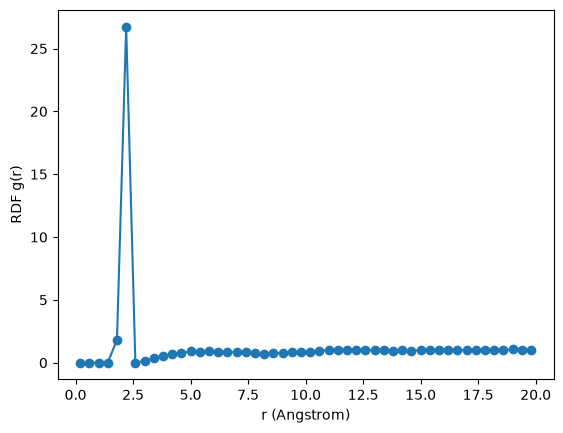

In [4]:
plt.plot(rdf.distance.values, rdf.mean(dim='ts'), 'o-') # average over timesteps
plt.xlabel('r (Angstrom)')
plt.ylabel('RDF g(r)')
plt.show()

## Compute RDF of disulfide centers
As explained in the publication, sulfur - sulfur RDFs are dominated by the disulfide bond length.
Thus, to probe intermolecular distances, it is better to use the RDF of disulfude centers.

In [5]:
# in order to get the position of disulfide centers, we need to know which sulfurs are bonded together
# (note that there is no bond exchange observed for this data excerpt, but you could observe some for the higher temperatures)

bonds = bond_dynamics(path="../../data/BER/save/",
                      pattern="afd_325K.bond_data.bonds.nc",
                      restore=True
                      )

# list of bonded sulfurs for each timestep
connections = bonds.get_connections()

# Dataset of disulfide centers
bond_vectors = traj.add_bond_vectors(connections)

rdf = compute_rdf(
    bond_vectors.positions,
    bond_vectors.positions,
    traj.get_atoms().bounds,
    cutoff=25, n_bins=50)
rdf

	File list contains 1 files
	Bond Dynamics done!
	Computing RDF on timestep 10/10


<xarray.DataArray (ts: 10, distance: 50)> Size: 4kB
array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.49109451, 0.89241906, 0.91876354,
        1.17012046, 1.04527674, 0.79632703, 0.96094118, 0.83301874,
        0.47962883, 0.67723356, 0.76763577, 0.91588091, 0.78800369,
        0.87755721, 0.82775568, 0.92884433, 1.21879562, 1.12134611,
        0.9075138 , 0.99788292, 0.90834809, 0.99330599, 0.95359984,
        1.07547528, 0.98969484, 0.96901672, 1.02706382, 1.01487365,
        0.9914325 , 0.94823712, 1.17374576, 1.05135675, 1.04017056,
        1.00911723, 1.03335461, 0.95466937, 1.08184393, 0.96159243,
        1.03114561, 0.96168575, 0.98701364, 0.95653362, 1.001073  ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.40924801, 0.95616932, 0.96981208,
        1.0865473 , 1.04528334, 0.82582584, 1.01152343, 0.81110232,
        0.44126131, 0.71109973, 0.73753706, 0.88894885, 0.87287114,
        0.84465415, 0.81778789, 0.94706295, 1.20210738, 1.12135319,
        0.91460953, 0.99788923, 0.90835383, 0.97060799, 0.9694993 ,
        1.08539436, 0.97576164, 0.97775278, 1.02707031, 0.99551213,
        0.99875565, 0.96900756, 1.1508027 , 1.05136339, 1.05495238,
        1.00631268, 1.01194433, 0.98020148, 1.08185077, 0.97324014,
        0.99774547, 0.96808889, 0.98497636, 0.97026053, 1.00107932],
...
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.51119202, 1.0233272 ,
        1.08917877, 0.94303339, 0.8573911 , 1.06467187, 0.92294059,
        0.51925694, 0.67887802, 0.54317629, 0.87760023, 0.8385274 ,
        0.82470759, 1.10968658, 1.08628305, 1.15480962, 0.95468871,
        1.08028945, 0.92133446, 0.96555364, 0.91037069, 0.93467281,
        0.96878764, 1.09922598, 0.92323876, 0.96366604, 1.0522847 ,
        1.02317835, 1.04420595, 1.06156554, 1.04455543, 0.98937661,
        1.01156757, 1.04659814, 0.98513419, 1.01608081, 1.03394631,
        0.97560434, 1.00677129, 1.0160404 , 1.01190776, 0.91673468],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.08171933, 0.38185897, 1.01922996,
        1.00137034, 1.14798156, 1.00119242, 0.70693939, 0.80981132,
        0.78534425, 0.6761599 , 0.72133533, 0.76650658, 0.79885833,
        0.83235767, 0.91605773, 1.1910363 , 1.22519807, 1.03521733,
        1.01933445, 0.91764558, 0.99212087, 0.952062  , 0.88332613,
        1.01439127, 1.03915579, 0.9500484 , 0.91879025, 1.02486698,
        1.02273432, 1.09876407, 1.04422151, 0.95031104, 1.18603878,
        0.99909805, 0.96222252, 0.95570442, 1.10202332, 1.03213117,
        0.9183326 , 1.00699826, 1.03645554, 1.08613634, 0.93560902]])
Coordinates:
  * ts        (ts) int32 40B 1000000 1000010 1000020 ... 16000000 21000000
  * distance  (distance) float64 400B 0.25 0.75 1.25 1.75 ... 23.75 24.25 24.75

Now we have the RDF of disulfide centers.
We don't observe the 1st peak characteristic of intramolecular sulfur-sulfur distance and only get intermolecular data.

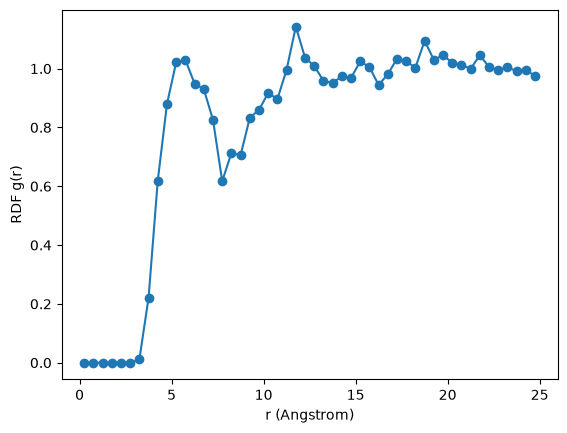

In [6]:
plt.plot(rdf.distance.values, rdf.mean(dim='ts'), 'o-')
plt.xlabel('r (Angstrom)')
plt.ylabel('RDF g(r)')
plt.show()